# Hands-on 10: Generator Data Konsumsi Energi Berbasis Jam Kerja

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 4.

Dataset energi 30 hari @ 10 menit dengan pola jam kerja/akhir pekan
(`data/synthetic/energy_30days.csv`), plus label hemat/boros
(`data/synthetic/energy_30days_labeled.csv`).

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Generate Dataset Energi

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/generate_energy_workhours.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Dataset energi disimpan ke: data/synthetic/energy_30days.csv (4320 baris)
            timestamp     device_id  power_watt
0 2026-01-01 00:00:00  energy-lab01       98.13
1 2026-01-01 00:10:00  energy-lab01      112.51
2 2026-01-01 00:20:00  energy-lab01      132.38
3 2026-01-01 00:30:00  energy-lab01      112.33
4 2026-01-01 00:40:00  energy-lab01      114.11
                           timestamp   power_watt
count                           4320  4320.000000
mean   2026-01-15 23:54:59.999999744   204.913956
min              2026-01-01 00:00:00    61.610000
25%              2026-01-08 11:57:30   126.610000
50%              2026-01-15 23:55:00   164.995000
75%              2026-01-23 11:52:30   308.425000
max              2026-01-30 23:50:00   481.470000
std                              NaN   101.698307



## 2. Label Hemat / Boros

In [3]:
r = subprocess.run([sys.executable, "scripts/label_energy_efficiency.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Label hemat/boros disimpan ke: data/synthetic/energy_30days_labeled.csv
[INFO] Ambang rata-rata: 204.91 watt
efficiency_label
hemat    2902
boros    1418
Name: count, dtype: int64
             timestamp     device_id  power_watt efficiency_label
0  2026-01-01 00:00:00  energy-lab01       98.13            hemat
1  2026-01-01 00:10:00  energy-lab01      112.51            hemat
2  2026-01-01 00:20:00  energy-lab01      132.38            hemat
3  2026-01-01 00:30:00  energy-lab01      112.33            hemat
4  2026-01-01 00:40:00  energy-lab01      114.11            hemat



## 3. Visualisasi

[SUKSES] outputs/figures/energy_week1.png
[SUKSES] outputs/figures/energy_hourly_profile.png
[SUKSES] outputs/figures/energy_labels.png



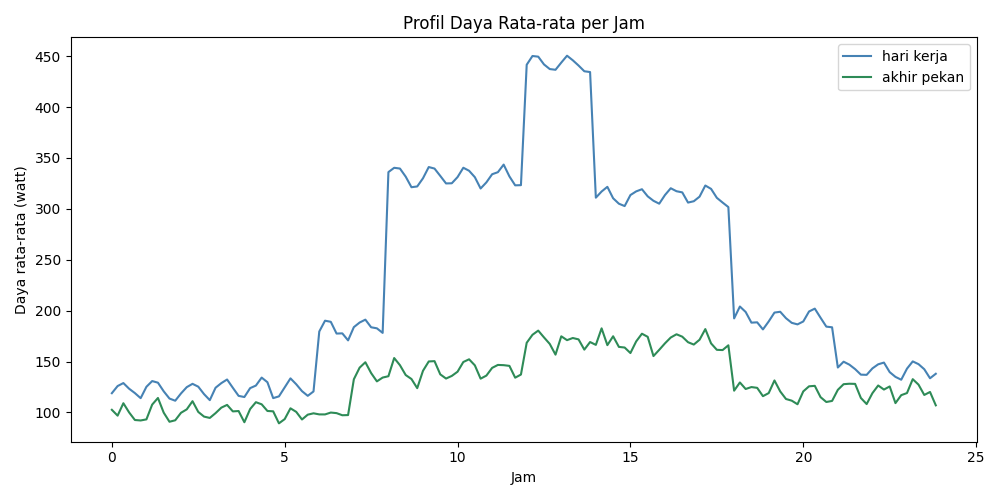

In [4]:
r = subprocess.run([sys.executable, "scripts/plot_energy_workhours.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/energy_hourly_profile.png")

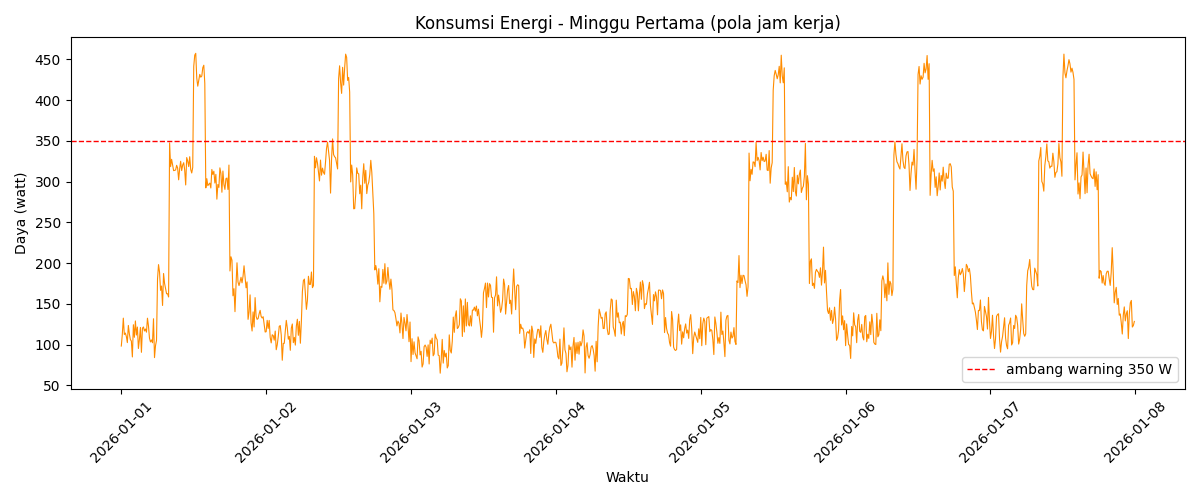

In [5]:
Image("outputs/figures/energy_week1.png")

## Penutup

Profil per jam menunjukkan puncak makan siang hari kerja (~430 W basis) dan akhir pekan
yang jauh lebih rendah. Ambang rata-rata 204.91 W memisahkan 2902 sampel hemat dan 1418
boros. Dataset ini menjadi bahan Hands-on 21 (dataset regresi) dan Hands-on 25 Bab 10
(forecasting energi harian).